# E0 – Baseline: M0 vs M1, M1b, M2

- **Goal:** Speed up optimization by grouping `8,760` hours into `~150–185` representative hours, and test three clustering versions against the full-year reference (**M0**).
- **Methods compared:**

| ID | Method | Key difference in plain terms |
|---|---|---|
| **M0** | Full year (reference) | No clustering — all `8,760` hours kept as ground truth. |
| **M1** | Current `main` | Groups hours and tries to keep peaks, but drops peaks in some stages of multi-stage models and slightly drifts annual totals. |
| **M1b** | Intermediate fix (PR #58) | Keeps peaks across all stages in multi-stage models, but annual totals still drift slightly. |
| **M2** | Proposed fix (#57) | Protects each series' peak and minimum as its own step and averages each group's members — exact annual totals and exact peaks across all stages. |

- **Test cases** (target: `150` steps for `demo`/`ms3`, `144` for `swissx`):
  - **demo**: small 1-stage model (`examples/clustering_demo`), solved.
  - **ms3**: synthetic 2-stage model (`models/ms3`), solved.
  - **swissx**: 178 real 4-stage profiles, clustering quality only (not solved).
- *Technical background (algorithm settings, commit IDs, exact differences, and metric definitions) is in the **Appendix** at the end.*

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join("..", "scripts")))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import romlab as rl

def try_run(*args):
    try:
        return rl.run(*args)
    except Exception as exc:  # failed runs are reported, not hidden
        return {"error": str(exc).strip().splitlines()[-1]}

print("Variants:", {k: v for k, v in rl.VARIANTS.items()})

Variants: {'M1': 'd436c9b7', 'M1b': 'f69e03d5', 'M2': 'bd1a0c89'}


In [2]:
TARGET = {"demo": 150, "ms3": 150, "swissx": 144}
MODE = {"demo": "rom", "ms3": "rom", "swissx": "cluster"}
VARS = ["M1", "M1b", "M2"]
prof = {c: rl.run(c, "M0", "profiles") for c in TARGET}
full = {c: rl.run(c, "M0", "full") for c in ("demo", "ms3")}
red = {(c, v): try_run(c, v, MODE[c], TARGET[c]) for c in TARGET for v in VARS}
for k, r in red.items():
    print(k, "ERROR: " + r["error"] if "error" in r else f"{r['num_ts']} clustered steps")

('demo', 'M1') 178 clustered steps
('demo', 'M1b') 178 clustered steps
('demo', 'M2') 178 clustered steps
('ms3', 'M1') 178 clustered steps
('ms3', 'M1b') 178 clustered steps
('ms3', 'M2') 178 clustered steps
('swissx', 'M1') 185 clustered steps
('swissx', 'M1b') 185 clustered steps
('swissx', 'M2') 185 clustered steps


## 1. Sanity check: clustering structure per stage

- Checks that every stage has:
  - the same number of clustered steps,
  - `0` empty ("phantom") steps,
  - weights summing to `8,760` h.

Total phantom steps: 0 | Steps with weight != members: 0


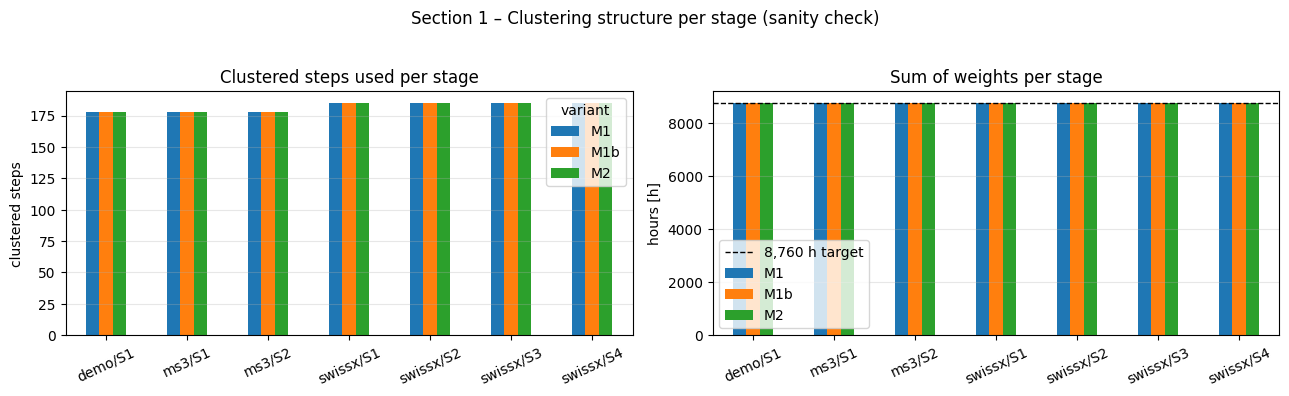

In [3]:
rows = []
for (c, v), r in red.items():
    if "error" in r:
        continue
    df = rl.stage_summary(r, prof[c]["num_horizon_ts"])
    df.insert(0, "variant", v); df.insert(0, "case", c)
    rows.append(df)
structure = pd.concat(rows, ignore_index=True)
structure["case_stage"] = structure["case"] + "/" + structure["stage"]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
used_p = structure.pivot(index="case_stage", columns="variant", values="used")[VARS]
used_p.plot.bar(ax=axes[0], rot=25)
axes[0].set_title("Clustered steps used per stage"); axes[0].set_ylabel("clustered steps"); axes[0].set_xlabel("")
axes[0].grid(axis="y", alpha=0.3)
wsum_p = structure.pivot(index="case_stage", columns="variant", values="weight_sum")[VARS]
wsum_p.plot.bar(ax=axes[1], rot=25, legend=False)
axes[1].axhline(8760, color="k", ls="--", lw=1, label="8,760 h target")
axes[1].set_title("Sum of weights per stage"); axes[1].set_ylabel("hours [h]"); axes[1].set_xlabel("")
axes[1].grid(axis="y", alpha=0.3); axes[1].legend()
fig.suptitle("Section 1 – Clustering structure per stage (sanity check)", y=1.03)
plt.tight_layout()
print(f"Total phantom steps: {int(structure['phantom'].sum())} | Steps with weight != members: {int(structure['weight_ne_members'].sum())}")

**Summary (Section 1):**
- All three methods produce identical step counts (`178` for `demo`/`ms3`, `185` for `swissx`), `0` phantom steps, and weights summing to `8,760` h.
- Phantom steps (issue 2) do not trigger on these datasets (they require near-identical extreme hours).

## 2. How well the clustered inputs match the full year

- Errors on non-constant input series (`0` = exact match; formulas in the **Appendix**):
  - `wsum_err`: annual totals
  - `max_err` / `min_err`: peaks and minima
  - `dc_nrmse`: sorted value distribution (duration curve)
  - `chr_nrmse`: hour-by-hour match

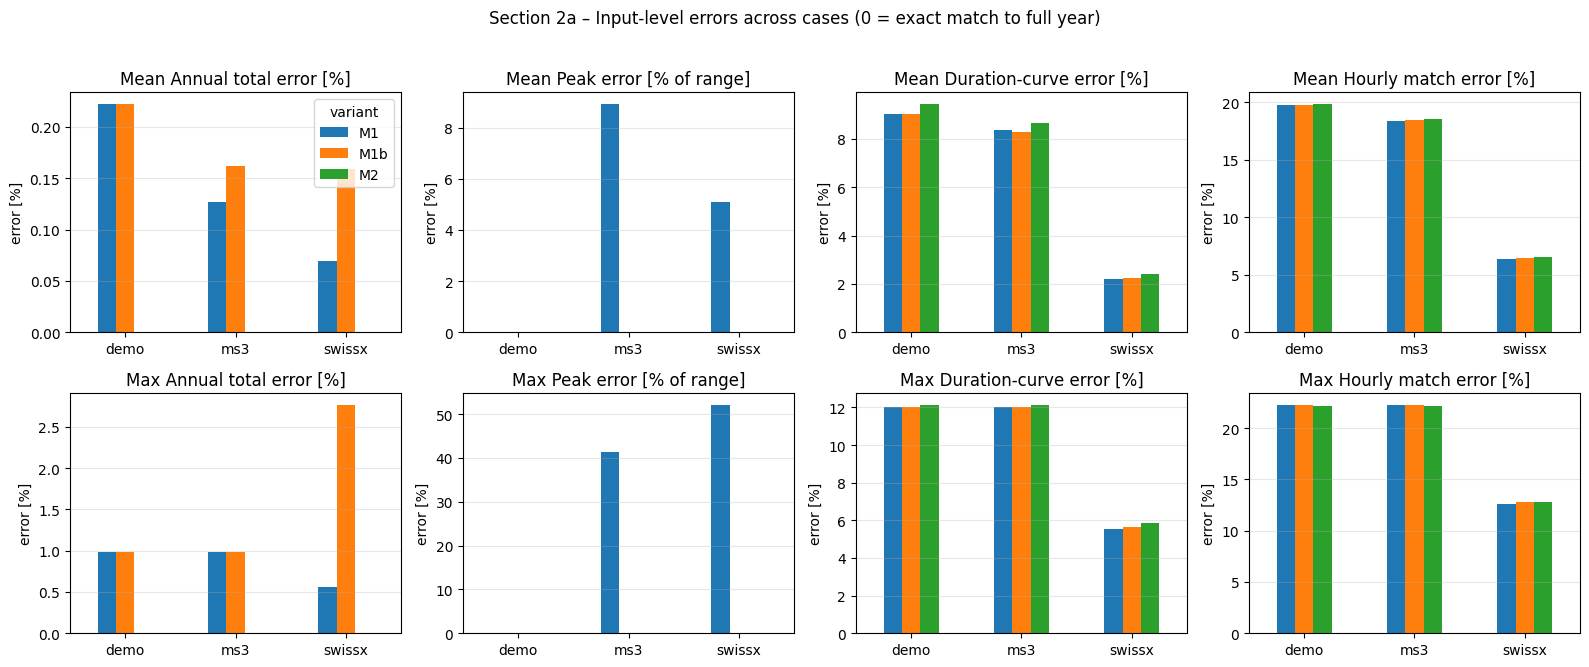

In [4]:
met = []
for (c, v), r in red.items():
    if "error" in r:
        continue
    df = rl.series_metrics(prof[c], r)
    df["case"], df["variant"] = c, v
    met.append(df)
met = pd.concat(met, ignore_index=True)
d = met[~met.constant].copy()
cols = [("wsum_err", "Annual total error [%]"), ("max_err", "Peak error [% of range]"),
        ("dc_nrmse", "Duration-curve error [%]"), ("chr_nrmse", "Hourly match error [%]")]
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for j, (col, title) in enumerate(cols):
    for i, agg in enumerate(["mean", "max"]):
        ax = axes[i, j]
        pt = d.assign(val=lambda x: x[col].abs() * 100).pivot_table(
            index="case", columns="variant", values="val", aggfunc=agg
        )[VARS]
        pt.plot.bar(ax=ax, rot=0, legend=(i == 0 and j == 0))
        ax.set_title(f"{agg.title()} {title}"); ax.set_xlabel("")
        ax.set_ylabel("error [%]"); ax.grid(axis="y", alpha=0.3)
fig.suptitle("Section 2a – Input-level errors across cases (0 = exact match to full year)", y=1.02)
plt.tight_layout()

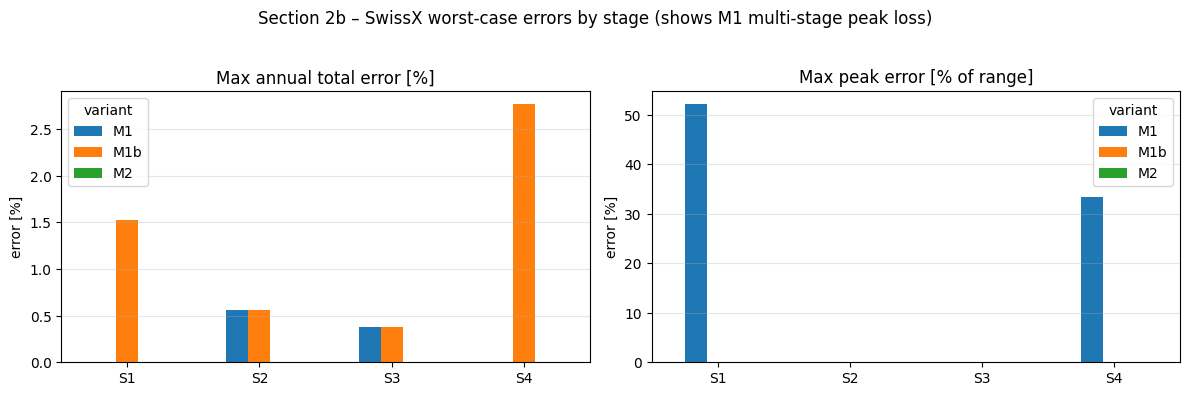

In [5]:
sx = d[d.case == "swissx"].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (col, title) in zip(axes, [("wsum_err", "Max annual total error [%]"), ("max_err", "Max peak error [% of range]")]):
    pt = sx.assign(val=lambda x: x[col].abs() * 100).pivot_table(
        index="stage", columns="variant", values="val", aggfunc="max"
    )[VARS]
    pt.plot.bar(ax=ax, rot=0)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel("error [%]"); ax.grid(axis="y", alpha=0.3)
fig.suptitle("Section 2b – SwissX worst-case errors by stage (shows M1 multi-stage peak loss)", y=1.03)
plt.tight_layout()

**Summary (Section 2):**
- **Annual totals (`wsum_err`):** exact only in `M2` (`≤ 3e-16`), vs. `0.07–0.2 %` mean and up to `2.8 %` max in `M1`/`M1b` (`swissx` S4).
- **Peaks (`max_err`):** `M1` loses multi-stage peaks (up to `41 %` in `ms3`, `52 %` in `swissx` S1/S4); `M1b` restores them (`≤ 1e-6`); `M2` is exact.
- **Shape (`dc_nrmse`, `chr_nrmse`):** `M2` is `3–9 %` higher at this `K` because `M1` pulls near-peak hours into extreme clusters (better high-end shape, biased totals).

## 3. Impact on optimization results (demo, ms3)

- Compares solved outputs against the full-year reference (`M0`):
  - total cost (`obj_err`),
  - installed capacities (`cap_abs_diff_rel`),
  - energy imports, exports, and load shedding.

Capacity diff vs M0: 0.0% | Technologies flipped: 0 (all capacities fixed)


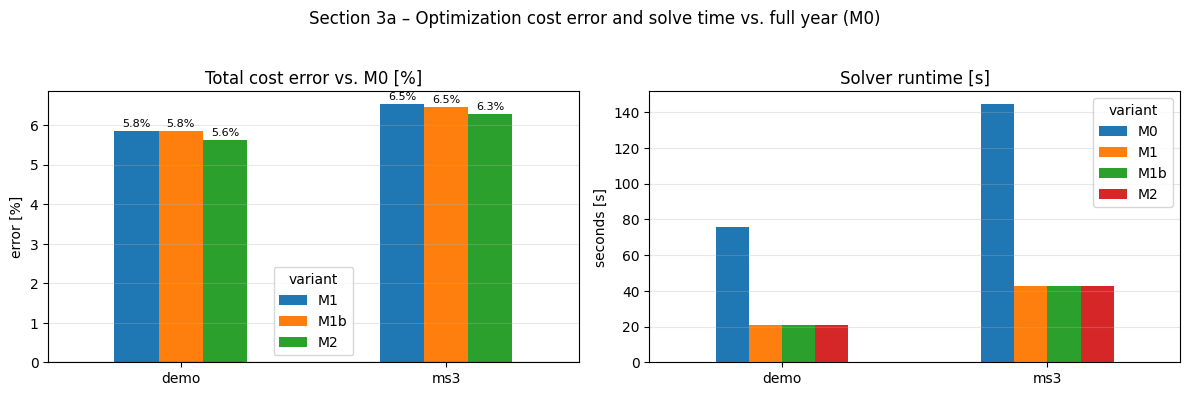

In [6]:
cmp = []
for c in ("demo", "ms3"):
    for v in VARS:
        r = red[(c, v)]
        cmp.append({"case": c, "variant": v, **rl.solution_compare(full[c], r)})
cmp_df = pd.DataFrame(cmp)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
obj_pt = cmp_df.assign(err=lambda x: x["obj_err"] * 100).pivot(index="case", columns="variant", values="err")[VARS]
obj_pt.plot.bar(ax=axes[0], rot=0)
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_title("Total cost error vs. M0 [%]"); axes[0].set_ylabel("error [%]"); axes[0].set_xlabel("")
axes[0].grid(axis="y", alpha=0.3)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f%%", fontsize=8, padding=2)
time_rows = [{"case": c, "variant": "M0", "secs_solve": full[c]["secs_solve"]} for c in ("demo", "ms3")]
time_df = pd.concat([pd.DataFrame(time_rows), cmp_df[["case", "variant", "secs_solve"]]], ignore_index=True)
time_pt = time_df.pivot(index="case", columns="variant", values="secs_solve")[["M0"] + VARS]
time_pt.plot.bar(ax=axes[1], rot=0)
axes[1].set_title("Solver runtime [s]"); axes[1].set_ylabel("seconds [s]"); axes[1].set_xlabel("")
axes[1].grid(axis="y", alpha=0.3)
fig.suptitle("Section 3a – Optimization cost error and solve time vs. full year (M0)", y=1.03)
plt.tight_layout()
print(f"Capacity diff vs M0: {cmp_df['cap_abs_diff_rel'].max():.1%} | Technologies flipped: {int(cmp_df['techs_flipped'].max())} (all capacities fixed)")

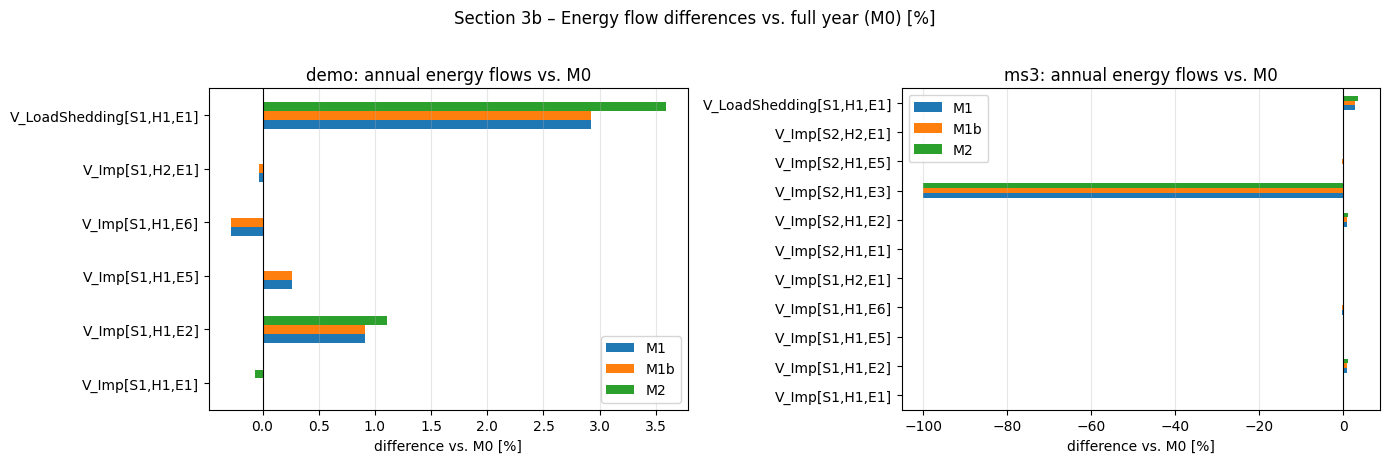

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, c in zip(axes, ("demo", "ms3")):
    runs = {"M0": full[c], **{v: red[(c, v)] for v in VARS}}
    ft = rl.flow_table(runs)
    ft = ft[ft["M0"].abs() > 1e-9]
    rel = (ft[VARS].div(ft["M0"], axis=0) - 1) * 100
    rel.plot.barh(ax=ax)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"{c}: annual energy flows vs. M0"); ax.set_xlabel("difference vs. M0 [%]")
    ax.grid(axis="x", alpha=0.3)
fig.suptitle("Section 3b – Energy flow differences vs. full year (M0) [%]", y=1.02)
plt.tight_layout()

**Summary (Section 3):**
- **Cost objective error vs. `M0`:** `demo` `+5.8 %` (`M1`/`M1b`) → `+5.6 %` (`M2`); `ms3` `+6.5 %` (`M1`/`M1b`) → `+6.3 %` (`M2`).
- **Energy flows:** demand-driven imports (`E5`, `E6`, `H2-E1`) are exact in `M2` vs. `0.3 %` off in `M1`; load shedding (`+3–4 %`) and `E2` import (`+1 %`) are high in all methods.
- **Design:** capacities are fixed in `demo`/`ms3`, so capacity differences are `0` (a free-capacity model is needed).

## Findings (E0)

- **Key takeaway:**
  - Differences *between* clustering methods are small (`≤ 0.3` percentage points in cost objective).
  - The shared error across all three methods is much larger (`≈ 6 %`).
  - The remaining gap comes from typical-hour ROM itself, not the bugs fixed in `#57` (see **E1**).
- **Clustering structure:**
  - Same step counts across all methods: `178` (`demo`, `ms3`) and `185` (`swissx`).
  - Every step has member hours (`0` phantom steps) and weights sum to `8,760` h.
  - Phantom steps (issue 2) do not trigger on these datasets; they require near-identical extreme hours (covered by unit tests).
- **Annual totals (`wsum_err`):**
  - `M2`: exact (`≤ 3e-16`) for every series.
  - `M1` / `M1b`: mean error `0.07–0.2 %`; max `1 %` (`demo`/`ms3`) and up to **`2.8 %`** (`M1b`, `swissx` S4).
- **Peaks & minima (`max_err`, `min_err`):**
  - `M1` (`main`) loses peaks/minima on any stage that initially gets fewer clusters than the largest stage (it re-clusters those stages with extreme protection turned off to equalize step counts):
    - `ms3`: clustered peak up to `41 %` of range below true peak.
    - `swissx`: up to `52 %` below true peak (stages S1 and S4).
  - `M1b`: fixes multi-stage peaks to `≤ 1e-6` (from `tsam` rounding).
  - `M2`: preserves peaks and minima **exactly**.
  - Single-stage `demo`: all methods keep peaks.
- **Profile shape (`dc_nrmse`, `chr_nrmse`):**
  - `M2` is `3–9 %` *higher* than `M1` at this target `K`.
  - Why: `M1` pulls near-peak hours into extreme clusters (better high-end shape, biased totals), whereas `M2` keeps totals exact and assigns near-peak hours to regular clusters.
  - This gap closes as `K` grows (see **E1**).
- **Optimization results (`demo`, `ms3`):**
  - Cost objective vs. full horizon (`M0`):
    - `demo`: `+5.8 %` (`M1`, `M1b`) → `+5.6 %` (`M2`).
    - `ms3`: `+6.5 %` (`M1`, `M1b`) → `+6.3 %` (`M2`).
  - Energy flows:
    - Demand-driven imports (`E5`, `E6`, `H2-E1`): exact in `M2`, off by `0.3 %` in `M1`.
    - Load shedding (`+3–4 %`) and `E2` import (`+1 %`): elevated across all methods.
  - **Limitation:** all capacities in `demo`/`ms3` are fixed, so design differences cannot appear here — a free-capacity model is needed next.

## Appendix: Technical Background

### Shared ROM Setup

- **Reference (`M0`):** Unclustered full horizon (`8,760` h).
- **Clustered methods (`M1`, `M1b`, `M2`):**
  - Algorithm: `tsam` 1-hour typical periods (`hoursPerPeriod=1`), hierarchical Ward clustering (`rescaleClusterPeriods=False`).
  - Weights & storage:
    - Each horizon hour maps to one clustered step weighted by member count.
    - Storage state-of-charge remains tracked across all `8,760` h via the horizon → cluster map.
  - Size & stage rules:
    - Targets below `2 × max(series per stage)` are raised to that floor.
    - All stages in a multi-stage model share one common cluster count.
  - **E0 targets:** `150` (`demo`, `ms3`), `144` (`swissx`, matching thesis runs).

### Detailed Method Comparison

| ID | Code | Extreme periods (max/min) | Multi-stage sync | Cluster values | Key difference / issue |
|---|---|---|---|---|---|
| **M0** | `bd1a0c89` (branch) | None (`8,760` h) | — | Exact hourly data | Reference ground truth. |
| **M1** | `d436c9b7` (`main`) | `tsam` `new_cluster_center` (near-peak hours can join) | Re-cluster shorter stages to `num_ts_max` with `extremePeriodMethod="None"` | `tsam` `durationRepresentation` + rounding | Re-clustered stages lose extremes; weighted sums drift; phantom steps possible. |
| **M1b** | `f69e03d5` (PR #58) | Same `tsam` `new_cluster_center` | Re-cluster shorter stages with `num_ts + (num_ts_max - num_ts_s)` regular clusters, keeping `new_cluster_center` | Same `durationRepresentation` + rounding | Keeps multi-stage extremes (`= M1` on 1 stage); weighted-sum drift, phantom steps, slower 2-pass clustering. |
| **M2** | `bd1a0c89` (`57-rom-extreme-periods`) | Hand-picked per stage: each non-constant series' max & min extracted as a 1-hour cluster before `tsam` | Single pass to common `num_ts_reg + max_s(len(ext_s))` (shorter stages get more regular clusters) | **Exact mean** of member hours | Exact weighted sums, exact peaks/minima, no phantom steps, faster single-pass clustering. |

- **What each comparison isolates:**
  - `M1 → M1b`: Effect of keeping extreme periods during multi-stage sync (no change for 1-stage `demo`).
  - `M1/M1b → M2`: Effect of explicit 1-hour extremes + exact member means + single-pass sync.
  - `M1/M1b/M2 vs M0`: Baseline error of typical-hour ROM itself vs. full `8,760` h.

### Cases & Metric Definitions

- **swissx setup note:**
  - All `178` profiles enter as demand series of a pseudo system so clustering sees the same matrix as the full model.
  - Not solved (requires the wind module and hours of Gurobi runtime).
- **Structure metrics** (`stage_summary` in `scripts/romlab.py`):
  - `used`: clustered steps with `≥ 1` member hour.
  - `phantom`: clustered steps with `0` member hours (issue 2).
  - `weight_ne_members`: steps whose weight differs from their member count.
- **Input metrics** (`series_metrics` in `scripts/romlab.py`, non-constant series only; let $x$ = full hourly series, $r = \max(x) - \min(x)$, $v_k$ = clustered values, $w_k$ = cluster weights, and $\hat{x}_t = v_{c(t)}$ = rebuilt hourly series):
  - `wsum_err` (annual totals): $(\sum_k w_k v_k - \sum_t x_t) / |\sum_t x_t|$ (unnormalized $\sum_k w_k v_k - \sum_t x_t$ when $\sum_t x_t = 0$).
  - `max_err` / `min_err` (peaks and minima): $(\max_{w_k > 0} v_k - \max x) / r$ and $(\min_{w_k > 0} v_k - \min x) / r$.
  - `dc_nrmse` (duration curve): $\mathrm{RMSE}(\text{sort}_{\downarrow}(\text{repeat}(v_k, \text{round}(w_k))),\, \text{sort}_{\downarrow}(x)) / r$.
  - `chr_nrmse` (hour-by-hour match): $\mathrm{RMSE}(\hat{x}, x) / r$, measuring what the storage balance sees.
- **Model metrics** (`solution_compare` in `scripts/romlab.py`):
  - `obj_err`: relative objective cost error.
  - `cap_abs_diff_rel`: relative total capacity difference.
  - `techs_flipped`: count of built/unbuilt technology changes.
  - `secs_solve`: solver runtime in seconds.